# Lecture 04: Linear Regression
- Mục tiêu trong bài tập này:
  - Nắm vững được cách xây dựng model Linear Regression, Ridge Regression, Lasso Regression cơ bản trên bộ dataset có univariate và multivariate. 
  - Hiểu được tầm quan trọng của của hệ số **λ** trong Ridge Regression và Lasso Regression.
  - Hiểu được sự khác nhau của 3 model: Linear Regression, Ridge Regression và Lasso Regression.
  - Hiểu được sự hiệu quả của model khi chọn các features khi đưa vào train.
  - Hiểu được cách chọn features bằng Lasso Regression




In [87]:
# Import các thư viện sẽ dùng trong bài này
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.model_selection import cross_val_score
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

# Datasets

- Tên dữ liệu: [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance)
- Các thuộc tính của dữ liệu:
  - `age` (int64): Tuổi của người hưởng thụ

  - `sex` (object): Giới tính: female, male

  - `bmi` (float64): Chỉ số khối cơ thể, cung cấp hiểu biết về cơ thể, cân nặng tương đối cao hay thấp so với chiều cao, chỉ số khách quan về trọng lượng cơ thể ($kg/m^2$) sử dụng tỷ lệ chiều cao trên cân nặng, lý tưởng là $18,5$ đến $24,9$

  - `children` (int64): Số con tham gia BHYT/Số người phụ thuộc

  - `smoker` (object): Có hút thuốc hay không

  - `region` (object): Khu vực cư trú của người thụ hưởng ở US, Northeast, Southeast, Southwest, Northwest

  - `charges` (float64): Chi phí y tế cá nhân do bảo hiểm y tế thanh toán.

In [88]:
df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [89]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [90]:
df.shape

(1338, 7)

In [91]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [92]:
df.dtypes

age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

In [93]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

# Data Visualization

C:\Users\Phan Trong Dai\AppData\Local\Temp\ipykernel_9660\3528182416.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax = sns.distplot(df['charges'], kde = True, color = 'c')


Text(0.5, 1.0, 'Distribution of Charges')

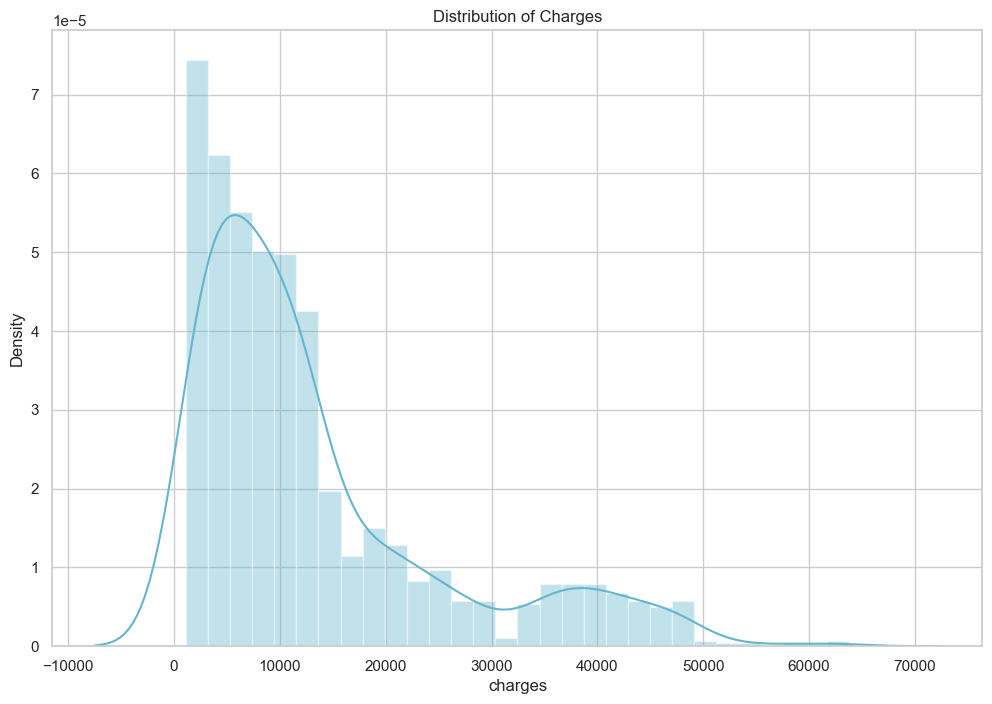

In [94]:
# Đầu tiên, ta sẽ quan sát xem `Charges` được phân phối như thế nào theo các factors được cho
sns.set(style='whitegrid')
f, ax = plt.subplots(1,1, figsize=(12, 8))
ax = sns.distplot(df['charges'], kde = True, color = 'c')
plt.title('Distribution of Charges')

Bây giờ ta sẽ visualize charges theo region

C:\Users\Phan Trong Dai\AppData\Local\Temp\ipykernel_9660\4221631780.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='region', y='charges', data=df, palette='Blues')


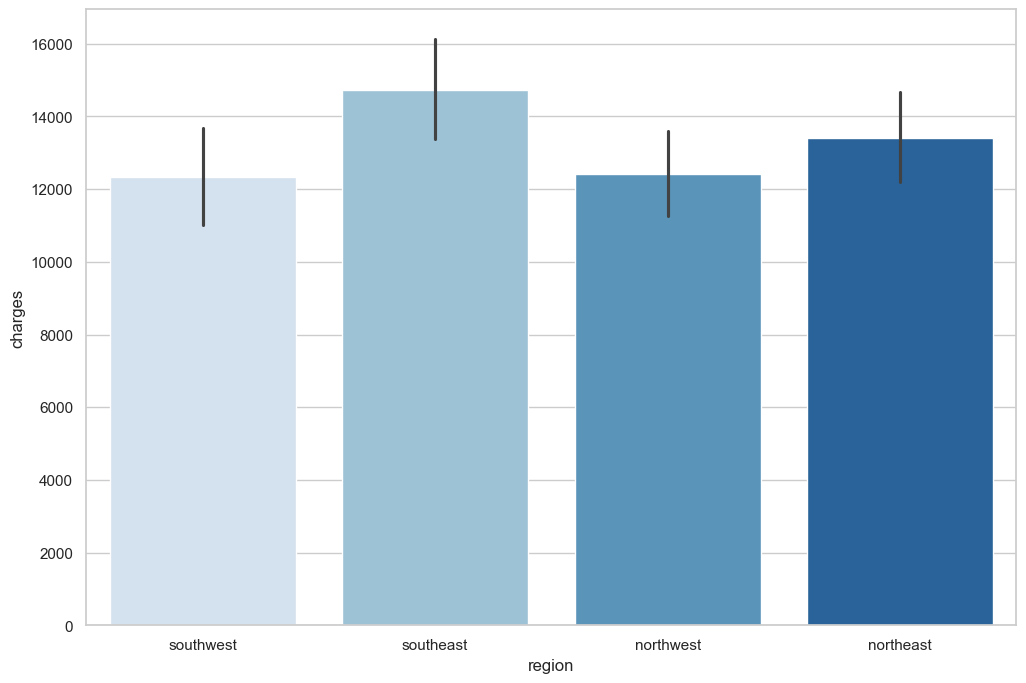

In [95]:
f, ax = plt.subplots(1, 1, figsize=(12, 8))
ax = sns.barplot(x='region', y='charges', data=df, palette='Blues')

Từ biểu đồ trên, ta thấy charges cao nhất là ở Southeast và thấp nhất là ở Southwest. Có tính đến các yếu tố nhất định (giới tính, hút thuốc, sinh con), hãy xem nó thay đổi như thế nào theo region

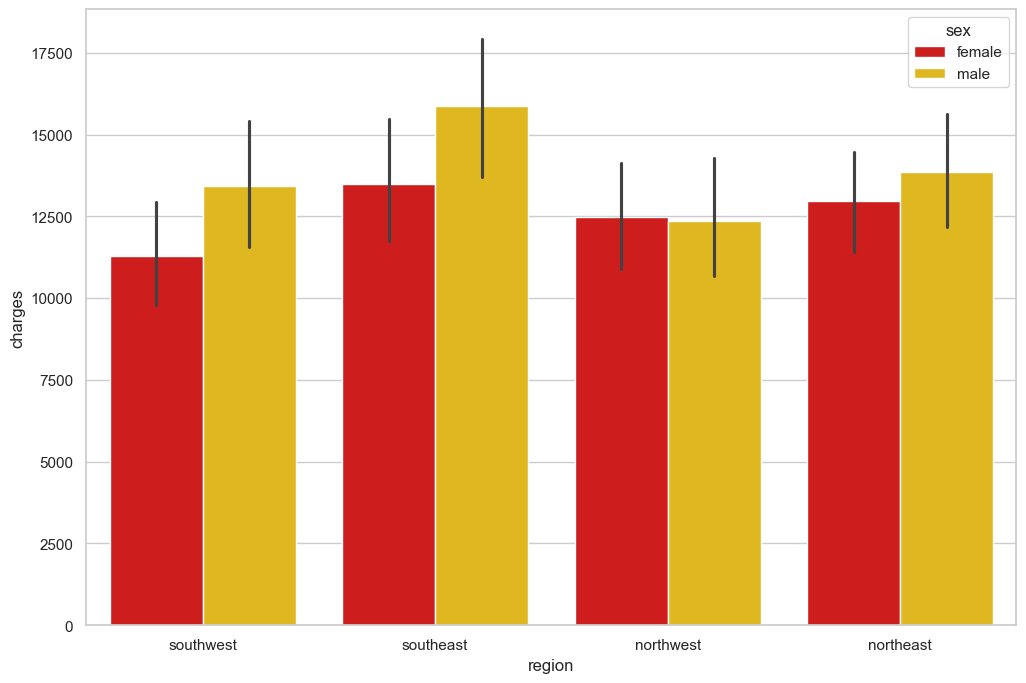

In [96]:
f, ax = plt.subplots(1, 1, figsize=(12, 8))
ax = sns.barplot(x='region', y='charges', hue='sex', data=df, palette='hot')

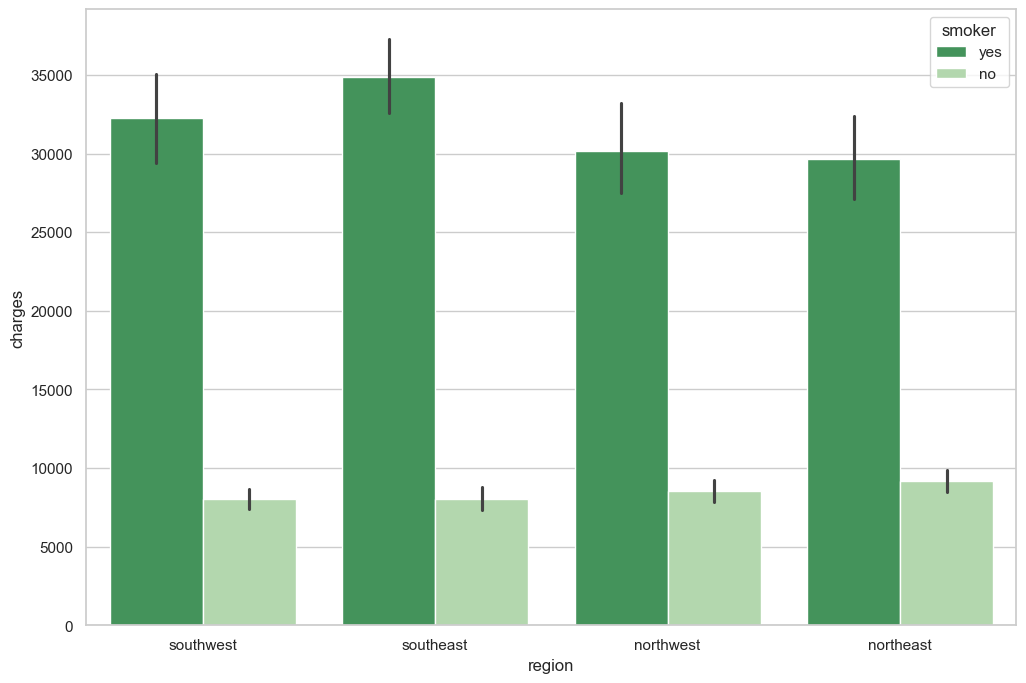

In [97]:
f, ax = plt.subplots(1,1, figsize=(12,8))
ax = sns.barplot(x = 'region', y = 'charges',
                 hue='smoker', data=df, palette='Greens_r')

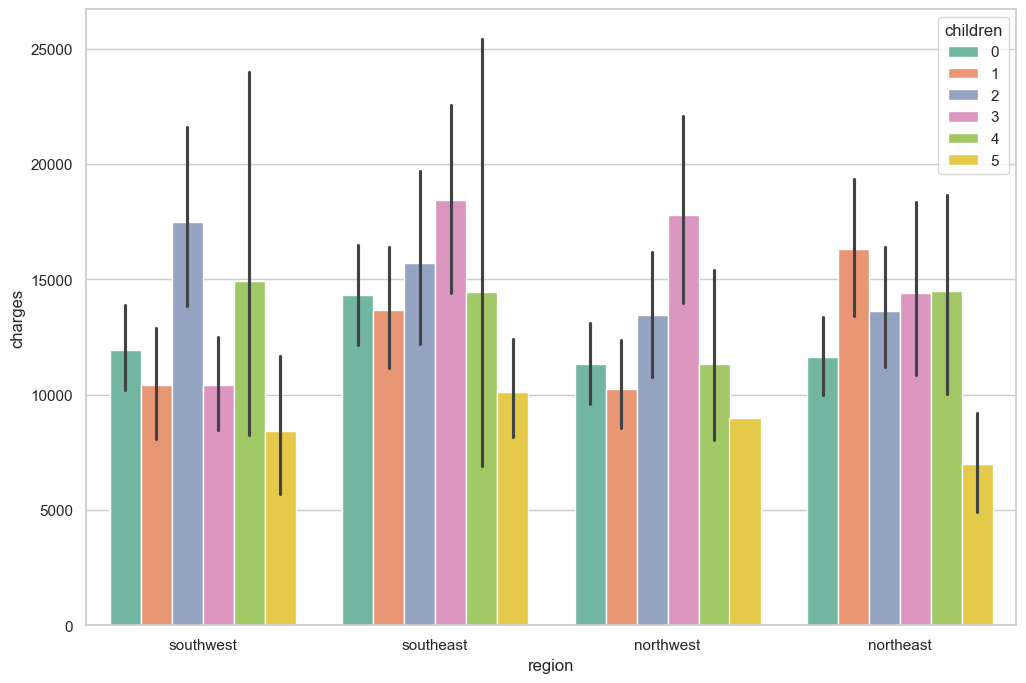

In [98]:
f, ax = plt.subplots(1, 1, figsize=(12, 8))
ax = sns.barplot(x='region', y='charges', hue='children', data=df, palette='Set2')

Như chúng ta có thể thấy từ các barplot này, charges do smoking cao nhất vẫn ở Southeast nhưng thấp nhất là ở Northeast. Những người ở Southwest thường hút thuốc nhiều hơn những người ở Northeast, nhưng những người ở Northeast có mức phí cao hơn theo giới tính so với ở Southwest và Northwest nói chung. Và những người có con cũng có xu hướng có chi phí y tế cao hơn

Bây giờ hãy phân tích chi phí y tế theo `age`, `chỉ số bmi` và `children` theo nhân tố `smoking`

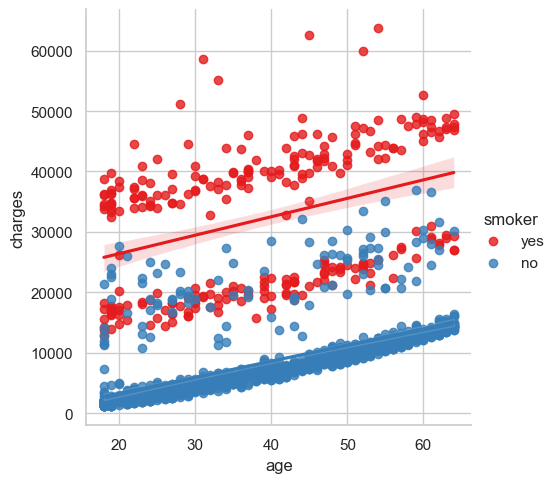

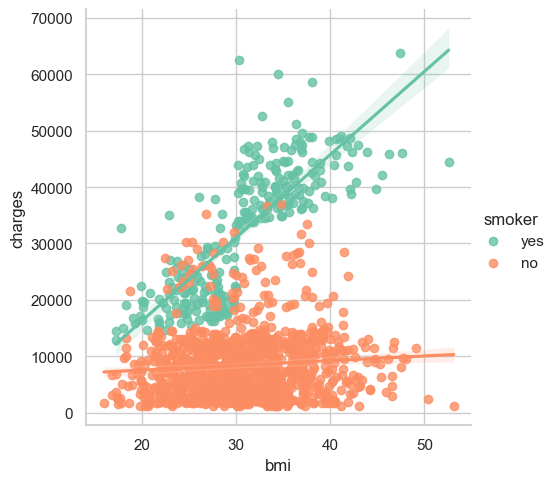

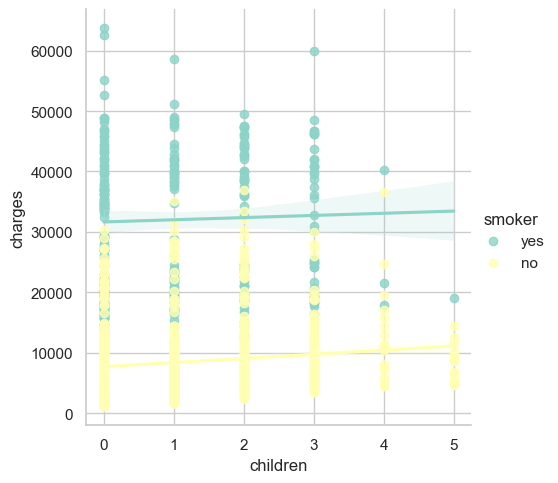

In [99]:
ax = sns.lmplot(x = 'age', y = 'charges', data=df, hue='smoker', palette='Set1')
ax = sns.lmplot(x = 'bmi', y = 'charges', data=df, hue='smoker', palette='Set2')
ax = sns.lmplot(x = 'children', y = 'charges', data=df, hue='smoker', palette='Set3')

Hút thuốc có tác động lớn nhất đến chi phí y tế, mặc dù chi phí đang tăng lên theo `age`, `chỉ số BMI` và `children`. Ngoài ra, những người có con thường ít hút thuốc hơn.

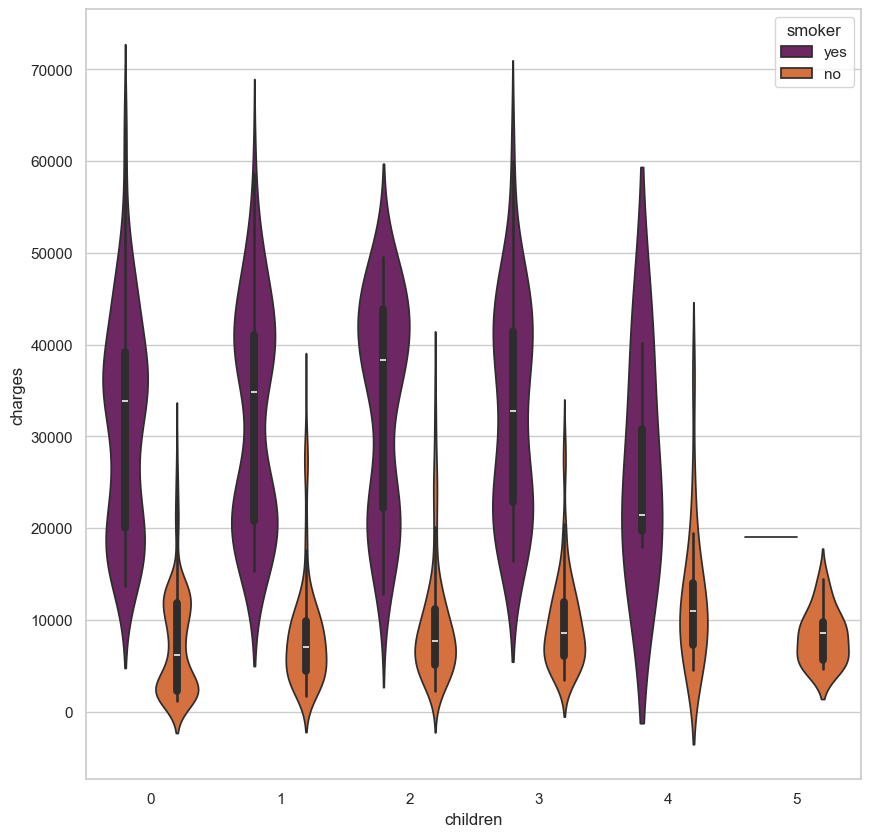

In [100]:
f, ax = plt.subplots(1, 1, figsize=(10, 10))
ax = sns.violinplot(x = 'children', y = 'charges', data=df,
                 orient='v', hue='smoker', palette='inferno')

In [101]:
# Converting objects labels into categorical
df[['sex', 'smoker', 'region']] = df[['sex', 'smoker', 'region']].astype('category')
df.dtypes

age            int64
sex         category
bmi          float64
children       int64
smoker      category
region      category
charges      float64
dtype: object

In [102]:
df['smoker']

0       yes
1        no
2        no
3        no
4        no
       ... 
1333     no
1334     no
1335     no
1336     no
1337    yes
Name: smoker, Length: 1338, dtype: category
Categories (2, object): ['no', 'yes']

In [103]:
# Converting category labels into numerical using LabelEncoder
from sklearn.preprocessing import LabelEncoder
label = LabelEncoder()
label.fit(df.sex.drop_duplicates())
df.sex = label.transform(df.sex)
label.fit(df.smoker.drop_duplicates())
df.smoker = label.transform(df.smoker)
label.fit(df.region.drop_duplicates())
df.region = label.transform(df.region)
df.dtypes

age           int64
sex           int64
bmi         float64
children      int64
smoker        int64
region        int64
charges     float64
dtype: object

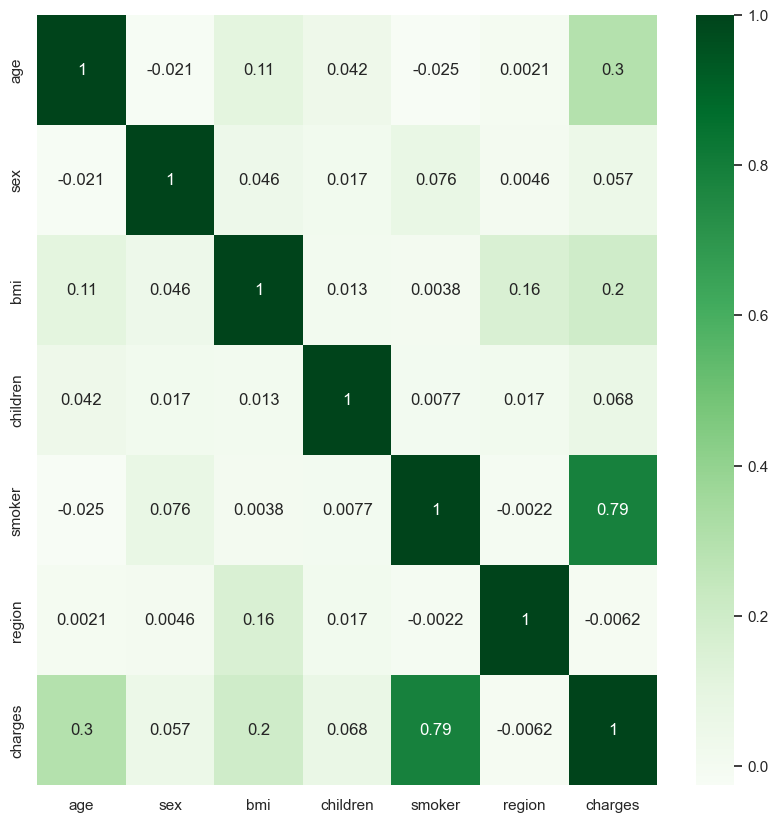

In [104]:
f, ax = plt.subplots(1, 1, figsize=(10, 10))
ax = sns.heatmap(df.corr(), annot=True, cmap='Greens')

# Bài tập 1: Sử dụng `bmi` để dự đoán `charges`. (univariate)

- Mục tiêu của bài này: 
  - Ôn tập lại cách sử dụng một số model trong thư viện sklearn cho bài toán Linear Regression.
  - Làm tiền đề để thấy rõ sự quan trọng của việc lựa chọn features cho vào model ảnh hưởng đến performent của model như thế nào.
  - Thấy được sự khác biệt về hiệu quả của 3 mô hình đã học.

In [105]:
X1 = np.array(df['bmi']).reshape(-1, 1)
y1 = np.array(df['charges']).reshape(-1, 1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=11)

In [106]:
# scale data
from sklearn.preprocessing import StandardScaler
X1scale = StandardScaler()
X1_train_scaled = X1scale.fit_transform(X1_train)
X1_test_scaled = X1scale.transform(X1_test)

In [107]:
# Checking the correlation
df.corr()

,age,sex,bmi,children,smoker,region,charges
age,1.000000,-0.020856,0.109272,0.042469,-0.025019,0.002127,0.299008
sex,-0.020856,1.000000,0.046371,0.017163,0.076185,0.004588,0.057292
bmi,0.109272,0.046371,1.000000,0.012759,0.003750,0.157566,0.198341
children,0.042469,0.017163,0.012759,1.000000,0.007673,0.016569,0.067998
smoker,-0.025019,0.076185,0.003750,0.007673,1.000000,-0.002181,0.787251
region,0.002127,0.004588,0.157566,0.016569,-0.002181,1.000000,-0.006208
charges,0.299008,0.057292,0.198341,0.067998,0.787251,-0.006208,1.000000


<Axes: xlabel='bmi', ylabel='charges'>

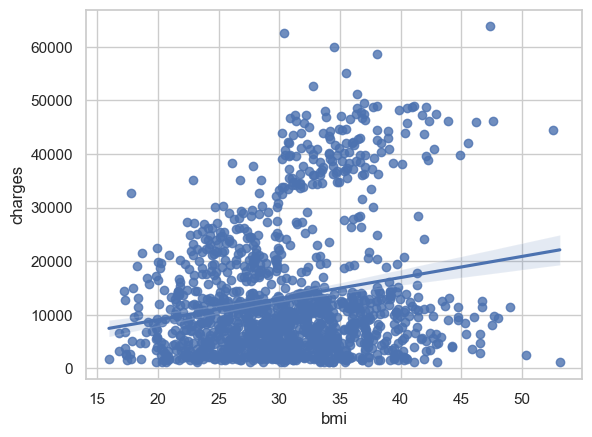

In [108]:
# Visualization of correlation between bmi and charges
sns.regplot(x=df['bmi'], y=df['charges'])

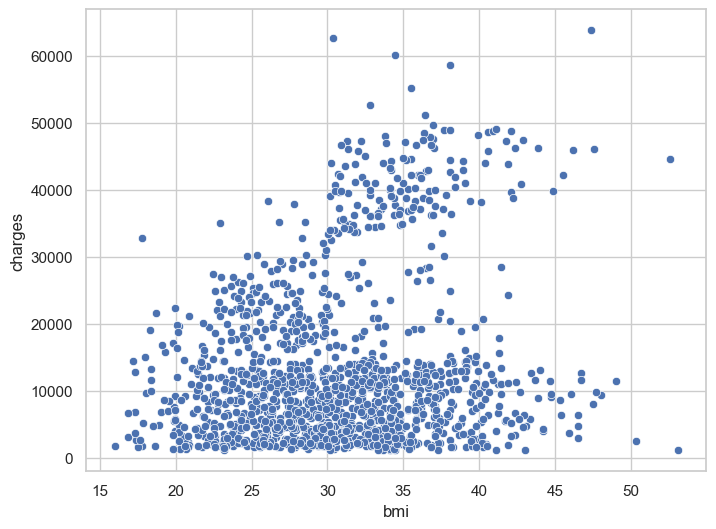

In [109]:
# Plot data
plt.figure(figsize=(8,6))
sns.scatterplot(x=df['bmi'],y=df['charges'])
plt.show()

## 1.1. Dùng model Linear Regression


In [110]:
def visualize(w0, w1, X_data, y_data):
  x = X_data
  y = w0 + X_data * w1
  plt.plot(x, y, c='b')
  plt.scatter(X_data, y_data, c='r')

In [111]:
'''
Hãy sử dụng thư viện LinearRegression để tìm bộ trọng số
'''
# *** START CODE HERE ***
lr = LinearRegression()
lr.fit(X1_train_scaled, y1_train)
# *** END CODE HERE ***

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Passed!!!


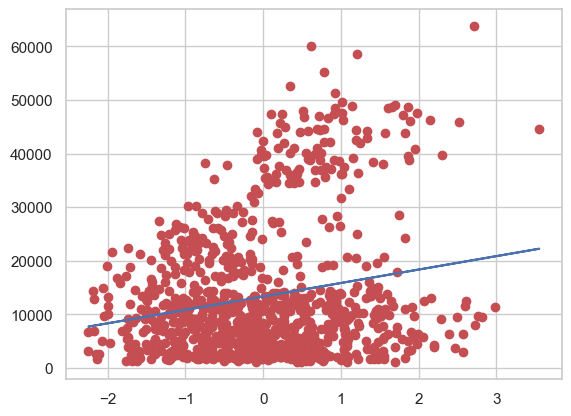

In [112]:
assert abs(lr.score(X1_test_scaled, y1_test) - 0.03208379370230274) < 1e-3
print("Passed!!!")
visualize(lr.intercept_[0], lr.coef_[0][0], X1_train_scaled, y1_train)

## 1.2. Dùng model Ridge regression 

In [113]:
'''
Hãy sử dụng Ridge (với alpha == 1) để tìm bộ trọng số của model
'''
# *** START CODE HERE ***
ridge = Ridge(alpha=1)
ridge.fit(X1_train_scaled, y1_train)
# *** END CODE HERE ***

,alpha,1
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [114]:
# Check your answer
assert abs(ridge.score(X1_test_scaled, y1_test) - 0.03209311935837611) < 1e-3
print("Passed!!!")

Passed!!!


## 1.3. Dùng model Lasso regression

In [115]:
'''
Hãy sử dụng Lasso (với alpha == 1) để tìm bộ trọng số của model
'''
# *** START CODE HERE ***
lasso = Lasso(alpha=1)
lasso.fit(X1_train_scaled, y1_train)
# *** END CODE HERE ***

,alpha,1
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


Passed!!!


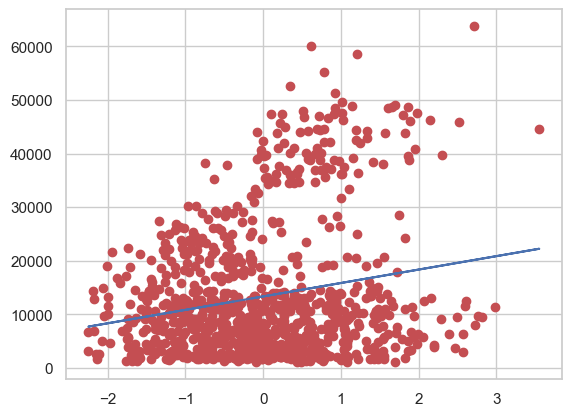

In [116]:
# Check your answer
assert abs(lasso.score(X1_test_scaled, y1_test) - 0.03208729545155509) < 1e-3
print("Passed!!!")
visualize(lasso.intercept_[0], lasso.coef_[0], X1_train_scaled, y1_train)

## 1.4. Dự đoán giá trị của một điểm dữ liệu thông qua model LinearRegression của sklearn

In [117]:
'''
Hãy dự đoán số tiền phải chi trả cho điểm dữ liệu đầu tiên trong tập test. Tức là X_test[0]
'''
# *** START CODE HERE ***
# Scale dữ liệu cần predict
dt = X1scale.transform(X1_test[0].reshape(-1, 1))
ans = lr.predict(dt)
ans = ans[0][0]
print(ans)
# *** END CODE HERE ***

14988.710768185125


In [118]:
# Check your answer
assert abs(ans - 14988.710768185125) < 1e-3
print("Passed!!!")

Passed!!!


#### Xem kết quả ở trên và chọn model có hiệu quả tốt nhất

In [119]:
# Mô hình nào là mô hình tốt nhất trong 3 mô hình dưới đây (theo r2 score)
choices = ['Linear Regression', 'Ridge Regression', 'Lasso Regression']
your_choice = 1
print("Mô hình có hiệu quả tốt nhất (theo R2 Score) là {}".format(choices[your_choice]))

Mô hình có hiệu quả tốt nhất (theo R2 Score) là Ridge Regression


# Bài tập 2: Sử dụng nhiều đặc trưng để dự đoán charges (multivariate). Chọn giá trị λ tốt nhất để đưa vào model Ridge và Lasso.
- Mục tiêu của bài này:
  - Hiểu được cách chọn nhiều đặc trưng để đưa vào các model Linear Regression.
  - Hiểu được tầm quan trọng của các đặc trưng đưa vào model.
  - Biết được cách chọn giá trị λ tốt nhất để đưa vào model và tầm quan trọng của λ đối với hiệu quả của model.
  - Hiểu được sự khác nhau của 3 model: Linear Regression, Ridge Regression và Lasso Regression thông qua các metrics đánh giá

## 2.1. Sử dụng nhiều đặc trưng để đưa vào model Linear Regression

In [120]:
X = df.drop(['charges'], axis = 1)
y = df['charges']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=11)

In [121]:
# Giữ dữ liệu chưa scale để dùng trong cross-validation.
X_train_raw = X_train.copy()

# Scale data cho bước huấn luyện và đánh giá cuối cùng.
Xscale = StandardScaler()
X_train = Xscale.fit_transform(X_train)
X_test = Xscale.transform(X_test)

In [122]:
"""
Sử dụng Linear Regression để huấn luyện mô hình trên X_train, y_train và đánh giá mô hình trên X_test, y_test
"""
# *** START CODE HERE ***
lr = LinearRegression()
lr.fit(X_train, y_train)
print(lr.score(X_test, y_test))
# *** END CODE HERE ***

0.7658208751054745


In [123]:
# Dựa vào kết quả cell trên và kết quả của bài 1, hãy tự rút ra kết luận của bản thân!
choices = ['univariate', 'multivariate']
your_choice = 1
print("Hiệu quả của model khi sử dụng {} features tốt hơn".format(choices[your_choice]))

Hiệu quả của model khi sử dụng multivariate features tốt hơn


## 2.2. Tìm giá trị λ tốt nhất để đưa vào model Ridge Regression và Lasso Regression.

### 2.2.1. Ridge regression

6.6000000000000005 0.7372681304602746


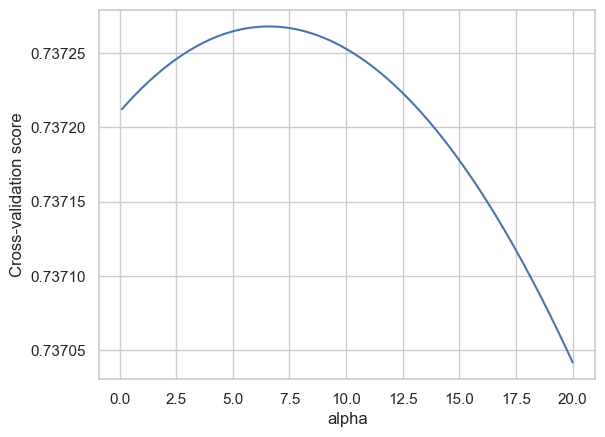

In [124]:
# Tạo các giá trị alpha để phù hợp cho việc lựa chọn

'''
  Mục tiêu của hàm này là tìm giá trị alpha tốt nhất cho model Ridge Regression. Từ đó thấy được tầm quan trọng của tham số 
  alpha đối với model.

  Hàm này sẽ trả về 4 giá trị: 
    - best_alpha
    - best_score: là giá trị cross-validation tốt nhất ứng với giá trị best_alpha
    - alphas: tập các giá trị alpha để mình lựa chọn
    - scores: tập các giá trị ứng với các giá trị alpha trong tập alphas
  

  Hint:
    - Sử dụng phương pháp `cross validation` với cv = 5 để chọn giá trị alpha tốt nhất.
    - Dùng make_pipeline(StandardScaler(), Ridge(alpha=alpha)) hoặc Lasso tương ứng.
    - Truyền X_train_raw, y_train vào cross_val_score để scaler chỉ fit trên mỗi fold train.
'''
def find_best_alpha_ridge():
  step = 0.1
  alphas = np.arange(step, 20 + step, step)

  # *** START CODE HERE ***
  best_alpha = None
  best_score = float('-inf')
  scores = []
  for alpha in alphas:
      ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
      score = cross_val_score(ridge, X_train_raw, y_train, cv=5)
      avg_score = np.mean(score)
      if avg_score > best_score:
          best_alpha = alpha
          best_score = avg_score
      scores.append(np.mean(score))
  return best_alpha, best_score, alphas, scores
  # *** END CODE HERE ***

# Driver code - No need to change anything

# Vẽ đồ thị biểu diễn sự khác nhau của cross-validation score với các giá trị alpha
best_alpha_ridge, best_score_ridge, alphas_ridge, scores_ridge = find_best_alpha_ridge()
print(best_alpha_ridge, best_score_ridge)
plt.plot(alphas_ridge, scores_ridge)
plt.xlabel('alpha')
plt.ylabel('Cross-validation score')
plt.show()

In [125]:
# Run this cell to test your result
assert abs(best_score_ridge-0.737)<1e-3 and abs(best_alpha_ridge-6.6) <= 1e-1
print("Passed!!!")

Passed!!!


### 2.2.2. Lasso Regression

20.0 0.7373063777595562


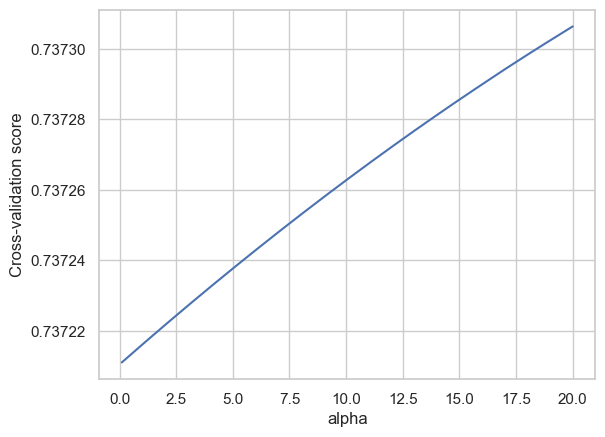

In [126]:
# Tạo các giá trị alpha để phù hợp cho việc lựa chọn


'''
  Mục tiêu của hàm này là tìm giá trị alpha tốt nhất cho model Lasso Regression. Từ đó thấy được tầm quan trọng của tham số 
  alpha đối với model.

  Hàm này sẽ trả về 4 giá trị: 
    - best_alpha
    - best_score: là giá trị cross-validation tốt nhất ứng với giá trị best_alpha
    - alphas: tập các giá trị alpha để mình lựa chọn
    - scores: tập các giá trị ứng với các giá trị alpha trong tập alphas
  

  Hint:
    - Sử dụng phương pháp `cross validation` với cv = 5 để chọn giá trị alpha tốt nhất.
    - Dùng make_pipeline(StandardScaler(), Ridge(alpha=alpha)) hoặc Lasso tương ứng.
    - Truyền X_train_raw, y_train vào cross_val_score để scaler chỉ fit trên mỗi fold train.
'''
def find_best_alpha_lasso():
  step = 0.1
  alphas = np.arange(step, 20 + step, step)

  # *** START CODE HERE ***

  best_alpha = None
  best_score = float('-inf')
  scores = []
  for alpha in alphas:
      lasso = make_pipeline(StandardScaler(), Lasso(alpha=alpha))
      score = cross_val_score(lasso, X_train_raw, y_train, cv=5)
      avg_score = np.mean(score)
      if avg_score > best_score:
          best_alpha = alpha
          best_score = avg_score
      scores.append(np.mean(score))
  return best_alpha, best_score, alphas, scores
  # *** END CODE HERE ***

# Driver code - No need to change anything

# Vẽ đồ thị biểu diễn sự khác nhau của cross-validation score với các giá trị alpha
best_alpha_lasso, best_score_lasso, alphas_lasso, scores_lasso = find_best_alpha_lasso()
print(best_alpha_lasso, best_score_lasso)
plt.plot(alphas_lasso, scores_lasso)
plt.xlabel('alpha')
plt.ylabel('Cross-validation score')
plt.show()

In [127]:
# Run this cell to test your result
assert abs(best_score_lasso- 0.737)<1e-3 and abs(best_alpha_lasso-20) <= 1e-1
print("Passed!!!")

Passed!!!


### 2.2.3. Đánh giá sự hiệu quả của 3 model: Linear Regression, Ridge Regression, Lasso Regression thông qua 2 metrics: R2 Score và Mean Squaed Error (MSE).

In [128]:
"""
    Lần lượt huấn luyện 3 mô hình Linear Regression, Ridge Regression, Lasso Regression trên tập train.
        - Sử dụng LinearRegression, Ridge, Lasso từ thư viện sklearn để tạo model.
    Lưu ý sử dụng best_alpha tương ứng với mỗi mô hình.
    Đánh giá hiệu suất của các mô hình trên tập test qua 2 độ đo: R2 Score và Mean Squared Error:
        - Sử dụng hàm r2_score và mean_squared_error của sklearn để tính toán.
"""
# *** START CODE HERE ***
lr = LinearRegression()
ridge = Ridge(alpha=best_alpha_ridge)
lasso = Lasso(alpha=best_alpha_lasso)

# Train các model
lr.fit(X_train, y_train)
ridge.fit(X_train, y_train)
lasso.fit(X_train, y_train)

# Đánh giá hiệu suất của model trên tập test
lr_predict = lr.predict(X_test)
ridge_predict = ridge.predict(X_test)
lasso_predict = lasso.predict(X_test)

# Đánh giá trên metric R2 Score
lr_predict_r2 = r2_score(y_test, lr_predict)
ridge_predict_r2 = r2_score(y_test, ridge_predict)
lasso_predict_r2 = r2_score(y_test, lasso_predict)

# Đánh giá trên metric Mean_squared_error
lr_predict_mse = mean_squared_error(y_test, lr_predict)
ridge_predict_mse = mean_squared_error(y_test, ridge_predict)
lasso_predict_mse = mean_squared_error(y_test, lasso_predict)

# *** END CODE HERE ***

print("Linear Regression R2 Score:", lr_predict_r2)
print("Ridge Regression R2 Score:", ridge_predict_r2)
print("Lasso Regression R2 Score:", lasso_predict_r2)
print("----------------------------------------------")
print("Linear Regression MSE:", lr_predict_mse)
print("Ridge Regression MSE:", ridge_predict_mse)
print("Lasso Regression MSE:", lasso_predict_mse)

Linear Regression R2 Score: 0.7658208751054745
Ridge Regression R2 Score: 0.7657802319663626
Lasso Regression R2 Score: 0.7662287279182778
----------------------------------------------
Linear Regression MSE: 32867415.517937914
Ridge Regression MSE: 32873119.847654518
Lasso Regression MSE: 32810172.721960243


In [129]:
# Hãy quan sát kết quả ở cell trên và tự rút ra kết quả cho mình!
choices = ['Linear Regression', 'Ridge Regression', 'Lasso Regression']
your_choice_r2 = 2
your_choice_mse = 2
print("Mô hình có hiệu quả tốt nhất (theo R2 Score) là {}".format(choices[your_choice_r2]))
print("Mô hình có hiệu quả tốt nhất (theo MSE) là {}".format(choices[your_choice_mse]))

Mô hình có hiệu quả tốt nhất (theo R2 Score) là Lasso Regression
Mô hình có hiệu quả tốt nhất (theo MSE) là Lasso Regression


# Bài tập 3: Features selection bằng Lasso Regression
- Mục tiêu: Hiểu được cách chọn features bằng Lasso Regression

In [130]:
def features_selection(X, y):
  '''
    Mục tiêu của hàm này là trả về các đặc trưng được chọn thông qua model Lasso Regression

    Yêu cầu:
      - Sử dụng model Lasso Regression với giá trị alpha tốt nhất đã tìm được ở bài tập trước để chọn features.

    Hints:
      - Chọn các đặc trưng có trọng số khác 0.
  '''
  # *** START CODE HERE ***
  lasso = Lasso(alpha=best_alpha_lasso)
  lasso.fit(X, y)

  # Features selection
  selected_features = np.where(lasso.coef_ != 0)[0]
  return selected_features

  # *** END CODE HERE ***

selected_features = features_selection(X_train, y_train)

print("Selected features indices:", selected_features)

Selected features indices: [0 1 2 3 4 5]


In [131]:
assert (selected_features == [0, 1, 2, 3, 4, 5]).all()